# Diamonds

In this task I try to find what changes the price of a diamond.

Columns I will use:

| Column | Meaning |
|---|---|
| carat | weight |
| cut | quality of the cut |
| color | color grade |
| clarity | clarity grade |
| price | price in dollars |
| x, y, z | size in mm |

## Libraries

- pandas: tables and csv files
- numpy: arrays
- matplotlib: plots
- seaborn: only to download the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Loading the data

First I download the data, save it as csv, and read it again with pandas.

In [2]:
sns.load_dataset("diamonds").to_csv("diamonds.csv", index=False)

df = pd.read_csv("diamonds.csv")
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


## DataFrame

In [3]:
df.shape

(53940, 10)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  str    
 2   color    53940 non-null  str    
 3   clarity  53940 non-null  str    
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), str(3)
memory usage: 4.7 MB


In [5]:
df.isna().sum()

carat      0
cut        0
color      0
clarity    0
depth      0
table      0
price      0
x          0
y          0
z          0
dtype: int64

In [6]:
print(df.duplicated().sum())
df.drop_duplicates(inplace=True)
df.shape

146


(53794, 10)

In [7]:
df["price_per_carat"] = df["price"] / df["carat"]
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z,price_per_carat
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43,1417.391304
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31,1552.380952
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31,1421.739130
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63,1151.724138
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75,1080.645161


In [8]:
df["cut"].value_counts()

cut
Ideal        21488
Premium      13748
Very Good    12069
Good          4891
Fair          1598
Name: count, dtype: int64

Average price for each cut.

In [9]:
cuts = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
avg_price = []

for c in cuts:
    cut_data = df[df["cut"] == c]
    avg_price.append(cut_data["price"].mean())
    print(c, cut_data["price"].mean())

Fair 4341.954317897372
Good 3919.1210386424045
Very Good 3981.016157096694
Premium 4583.501891184173
Ideal 3462.7499534623976


In [10]:
df[df["carat"] > 3].sort_values("price", ascending=False).head()

,carat,cut,color,clarity,depth,table,price,x,y,z,price_per_carat
27684,3.01,Premium,J,SI2,60.7,59.0,18710,9.35,9.22,5.64,6215.946844
27685,3.01,Premium,J,SI2,59.7,58.0,18710,9.41,9.32,5.59,6215.946844
27679,3.51,Premium,J,VS2,62.5,59.0,18701,9.66,9.63,6.03,5327.920228
27649,3.01,Good,H,SI2,57.6,64.0,18593,9.44,9.38,5.42,6177.076412
27638,3.04,Premium,I,SI2,59.3,60.0,18559,9.51,9.46,5.62,6104.934211


## ndarray

In [11]:
prices = df["price"].to_numpy()

print(prices.shape)
print(prices.ndim)
print(prices.mean())

(53794,)
1
3933.065081607614


In [12]:
luxury = prices[prices > 10000]
print(len(luxury))

5203


In [13]:
sizes = df[["x", "y", "z"]].to_numpy()
print(sizes.shape)
sizes[:5]

(53794, 3)


array([[3.95, 3.98, 2.43],
       [3.89, 3.84, 2.31],
       [4.05, 4.07, 2.31],
       [4.2 , 4.23, 2.63],
       [4.34, 4.35, 2.75]])

Volume of the diamond = x * y * z

In [14]:
df["volume"] = sizes[:, 0] * sizes[:, 1] * sizes[:, 2]
df["volume"].describe()

count    53794.000000
mean       129.826975
std         78.160819
min          0.000000
25%         65.190168
50%        114.840180
75%        170.823600
max       3840.598060
Name: volume, dtype: float64

## Numeric

In [15]:
df[["carat", "depth", "table", "price"]].describe()

,carat,depth,table,price
count,53794.00000,53794.000000,53794.000000,53794.000000
mean,0.79778,61.748080,57.458109,3933.065082
std,0.47339,1.429909,2.233679,3988.114460
min,0.20000,43.000000,43.000000,326.000000
25%,0.40000,61.000000,56.000000,951.000000
50%,0.70000,61.800000,57.000000,2401.000000
75%,1.04000,62.500000,59.000000,5326.750000
max,5.01000,79.000000,95.000000,18823.000000


In [16]:
price = df["price"]

print("mean:", price.mean())
print("median:", price.median())
print("variance:", price.var())
print("std:", price.std())
print("skew:", price.skew())
print("kurtosis:", price.kurt())

mean: 3933.065081607614
median: 2401.0
variance: 15905056.948174471
std: 3988.1144602649597
skew: 1.6182398982654322
kurtosis: 2.1784530585226896


In [17]:
df[["carat", "depth", "table", "price"]].corr()

,carat,depth,table,price
carat,1.000000,0.027861,0.181091,0.921548
depth,0.027861,1.000000,-0.297669,-0.011048
table,0.181091,-0.297669,1.000000,0.126566
price,0.921548,-0.011048,0.126566,1.000000


## Plots

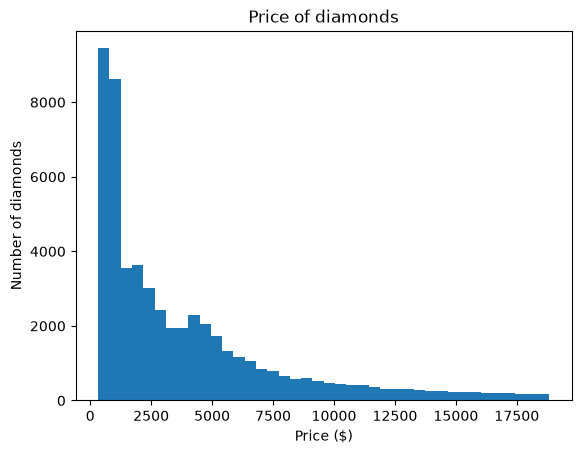

In [18]:
plt.hist(df["price"], bins=40)
plt.title("Price of diamonds")
plt.xlabel("Price ($)")
plt.ylabel("Number of diamonds")
plt.show()

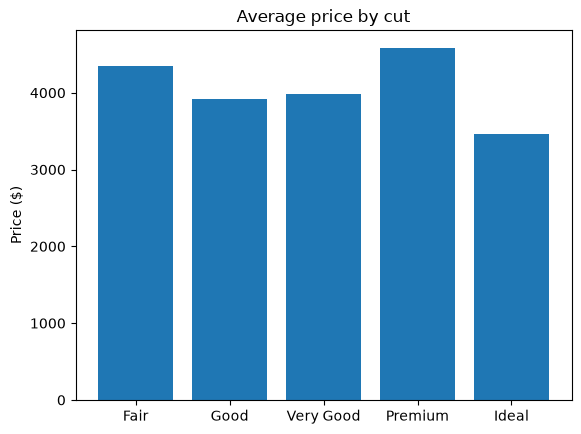

In [19]:
plt.bar(cuts, avg_price)
plt.title("Average price by cut")
plt.ylabel("Price ($)")
plt.show()

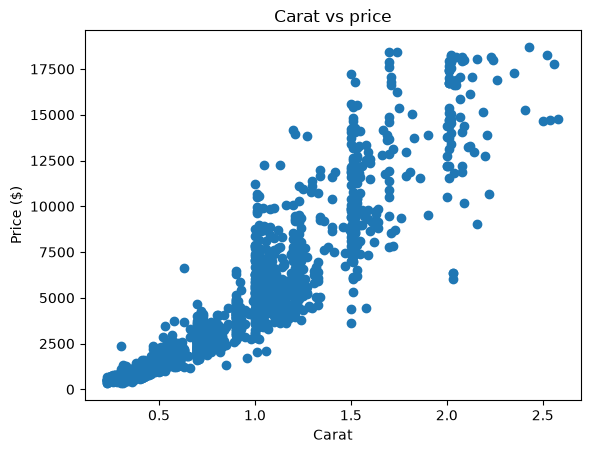

In [20]:
sample = df.sample(2000, random_state=1)

plt.scatter(sample["carat"], sample["price"])
plt.title("Carat vs price")
plt.xlabel("Carat")
plt.ylabel("Price ($)")
plt.show()

## Conclusion

- Carat has the strongest relation with price.
- Ideal cut has a lower average price than Premium, because Ideal diamonds are usually smaller.
- Most diamonds are cheap and a few are very expensive.